# Traditional DoE vs. Bayesian Optimization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sparks-baird/self-driving-lab-demo/blob/main/notebooks/escience/1.0-traditional-doe-vs-bayesian.ipynb)

The [first](https://youtu.be/Evua529dAgc) and
[second](https://youtu.be/41fQs4JxRQA) videos from Taylor Sparks' [Optimization Tutorial
YouTube playlist](https://youtube.com/playlist?list=PLL0SWcFqypClTIMQDOs_Jug70qaVPOzEc)
are based on the results from this notebook. I suggest watching these two videos prior
to working through this notebook for better context.

This notebook first describes uninformed
sampling methods including random, grid, and quasi-random (e.g., Latin hypercube, Sobol
sequences) and shows how quasi-random achieves a much more even distribution of points.
Finally, we compare the efficiency of these traditional methods for design of
experiments (DoE) against Bayesian optimization. We show that, on average, Bayesian
optimization is much more efficient than traditional DoE.

In [ ]:
try:
  import google.colab
  IN_COLAB = True
  %pip install git+https://github.com/sparks-baird/self-driving-lab-demo.git[ax-platform] # latest
  # %pip install self-driving-lab-demo[ax-platform] # uncomment for stable release
except:
  IN_COLAB = False

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
from scipy.stats import qmc
from os import path
from self_driving_lab_demo.utils.plotting import plot_and_save

In [2]:
bounds = {"x1": [0, 1], "x2": [0, 1]}
num_samples = 10

## Uninformed Sampling Methods

These are sampling methods that do not incorporate information about the objective function
to be optimized. We will cover grid search, random search, and two quasi-random methods:
Latin hypercube and Sobol sequences.

### Grid

Grid sampling is a structured approach to sampling from a search space. It involves
creating a grid of points over the space, and then selecting points from the grid. When
grids are used for certain types of problems (e.g., finite element methods), the
algorithms are often more straightforward than for non-lattice point sets. This can be
an effective way to ensure that the entire search space is explored, but it can also
lead to a lot of unnecessary points being generated, especially for high-dimensional
search spaces, due to large, systematic "pockets" in the search space.


In [3]:
from sklearn.model_selection import ParameterGrid

def get_grid_samples(bounds, num_samples = 10, seed=None):
    # seed is unused, for compatibility only
    param_grid = {}
    num_pts_per_dim = max(1, np.floor(num_samples ** (1 / len(bounds))).astype(int))
    for name, bnd in bounds.items():
        param_grid[name] = np.linspace(bnd[0], bnd[1], num=num_pts_per_dim)
    print(num_pts_per_dim)
    return pd.DataFrame(list(ParameterGrid(param_grid)))

grid_samples = get_grid_samples(bounds, num_samples=num_samples)
grid_samples

3


,x1,x2
0,0.0,0.0
1,0.0,0.5
2,0.0,1.0
3,0.5,0.0
4,0.5,0.5
5,0.5,1.0
6,1.0,0.0
7,1.0,0.5
8,1.0,1.0


In [4]:
grid_fig = px.scatter(grid_samples, x="x1", y="x2", width=400, height=400)
grid_fig

### Random

Random sampling is a simple and straightforward method for generating samples from a
search space. It involves randomly selecting points from the space, without any regard
for their distribution. This can be an effective method for exploring search spaces, and
it is often more effective than grid search. While it doesn't have the large, systematic
pockets characteristic of grid search, it has large, occasional gaps due to the random
nature of the search.

In [5]:
from numpy.random import default_rng

def get_random_samples(bounds, num_samples=9, seed=None):
    rng = default_rng(seed)
    samples = {}
    for parameter, bound in bounds.items():
        samples[parameter] = rng.uniform(bound[0], bound[1], num_samples)
    return pd.DataFrame(samples)

random_samples = get_random_samples(bounds, seed=0)
random_samples

,x1,x2
0,0.636962,0.935072
1,0.269787,0.815854
2,0.040974,0.002739
3,0.016528,0.857404
4,0.813270,0.033586
5,0.912756,0.729655
6,0.606636,0.175656
7,0.729497,0.863179
8,0.543625,0.541461


In [6]:
random_fig = px.scatter(random_samples, x="x1", y="x2", width=400, height=400)
random_fig

## Quasi-Random

Quasi-random sampling methods, also known as low-discrepancy or deterministic sampling methods, are a family of sampling techniques that are designed to
produce samples that are more evenly distributed than random samples. Unlike random
sampling, which selects points randomly and independently, quasi-random sampling methods
aim to achieve a more uniform coverage of the parameter space by reducing the
**discrepancy** between the generated points and the desired distribution.

We'll discuss two common quasi-random sampling methods: Latin hypercube and
Sobol sequences.

### Latin Hypercube

Latin hypercube sampling (LHS) is a variation of grid sampling that aims to improve the
uniformity of the samples. It does this by ensuring that each dimension of the search
space is represented equally in the sample set. It involves dividing the parameter space
into equally spaced intervals and randomly selecting one point within each interval. LHS
ensures a more even coverage of the parameter space compared to random or grid sampling
methods (i.e., lower discrepancy).

In [7]:
def get_latin_hypercube_samples(bounds, num_samples=10, seed=None):
    sampler = qmc.LatinHypercube(d=len(bounds), optimization="random-cd", seed=seed)
    samples = sampler.random(num_samples)
    l_bounds = [bound[0] for bound in bounds.values()]
    u_bounds = [bound[1] for bound in bounds.values()]
    samples = qmc.scale(samples, l_bounds, u_bounds)
    return pd.DataFrame(samples, columns=list(bounds.keys()))

latin_hypercube_samples = get_latin_hypercube_samples(bounds, seed=0)
latin_hypercube_samples

,x1,x2
0,0.245638,0.173021
1,0.436304,0.298347
2,0.927034,0.708724
3,0.114260,0.827050
4,0.718673,0.006493
5,0.013682,0.499726
6,0.595903,0.996641
7,0.639336,0.582434
8,0.318415,0.645854
9,0.870029,0.357731


In [8]:
latin_hypercube_fig = px.scatter(
    latin_hypercube_samples, x="x1", y="x2", width=400, height=400
)
latin_hypercube_fig


### Sobol Sequences

Sobol sequences are another type of quasi-random sampling with good space-filling (i.e.,
low discrepancy) properties. Sobol sequences "use a base of two to form successively
finer uniform partitions of the unit interval and then reorder the coordinates in each
dimension" ([source](https://en.wikipedia.org/wiki/Sobol_sequence)). In other words, to
obtain optimal space-filling properties, sample sizes that are powers of 2 (i.e.,
$n=2^m$) should be used. For each dimension,
Sobol sequences utilize a set of direction numbers, also known as primitive polynomials,
that are converted to a binary representation and undergo bitwise operations to arrive
at the final sequence.

In [9]:
from scipy.stats.qmc import Sobol

def get_sobol_samples(bounds, num_samples=10, seed=None):
    sampler = Sobol(len(bounds), seed=seed)
    samples = sampler.random(num_samples)
    
    l_bounds = [bound[0] for bound in bounds.values()]
    u_bounds = [bound[1] for bound in bounds.values()]
    samples = qmc.scale(samples, l_bounds, u_bounds)
    
    return pd.DataFrame(samples, columns=list(bounds.keys()))

sobol_samples = get_sobol_samples(bounds, num_samples=num_samples, seed=0)
sobol_samples

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



,x1,x2
0,0.850585,0.931366
1,0.451565,0.166937
2,0.248736,0.591645
3,0.584153,0.326728
4,0.663688,0.711389
5,0.014668,0.448486
6,0.312342,0.808678
7,0.897760,0.046263
8,0.987552,0.509826
9,0.339692,0.274682


In [10]:
sobol_fig = px.scatter(sobol_samples, x="x1", y="x2", width=400, height=400)
sobol_fig

### Comparison between sampling methods

The quasi-random methods tend to have better space-filling properties than random or
grid search. Note the large systematic gaps in grid, the large occasional gaps in
random, and the more even distribution of points in LHS and Sobol.

In [11]:
sampling_fns = dict(
    grid=get_grid_samples,
    random=get_random_samples,
    latin_hypercube=get_latin_hypercube_samples,
    sobol=get_sobol_samples,
)

sample_nums = [5, 10, 50, 100]
sample_nums.reverse()
        
sample_dfs = []
for name, sampling_fn in sampling_fns.items():
    for num_samples in sample_nums:
        sample_df = sampling_fn(bounds, num_samples)
        sample_df["name"] = name
        sample_df["num_samples"] = num_samples
        sample_dfs.append(sample_df)

compare_df = pd.concat(sample_dfs, axis=0)

10
7
3
2


C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



In [12]:
compare_df

,x1,x2,name,num_samples
0,0.000000,0.000000,grid,100
1,0.000000,0.111111,grid,100
2,0.000000,0.222222,grid,100
3,0.000000,0.333333,grid,100
4,0.000000,0.444444,grid,100
...,...,...,...,...
0,0.924471,0.379841,sobol,5
1,0.321745,0.816658,sobol,5
2,0.119724,0.066057,sobol,5
3,0.626250,0.628000,sobol,5


In [13]:
fig = px.scatter(
    compare_df,
    x="x1",
    y="x2",
    facet_row="num_samples",
    facet_col="name",
    width=800,
    height=800,
)
plot_and_save(
    "traditional-doe-compare",
    fig,
    show=True,
    mpl_kwargs=dict(width_inches=7.5, height_inches=8.0),
)


### Worsening performance in higher dimensions

As we observe the discrepancy associated with sampling methods in higher dimensions, we
notice that the gap between the quasi-random methods and the random and grid methods
widens. In other words, quasi-random methods increasingly outperform random and grid as
the dimensionality increases.

In [14]:
one = get_grid_samples(dict(x1=bounds["x1"]), num_samples=3**1)
two = get_grid_samples(dict(x1=bounds["x1"], x2=bounds["x2"]), num_samples=3**2)
three = get_grid_samples(
    dict(x1=bounds["x1"], x2=bounds["x2"], x3=[0.0, 1.0]), num_samples=3**3
)


3
3
3


In [15]:
# https://community.plotly.com/t/plotting-a-simple-1d-number-line/39169/4
import plotly.graph_objects as go
fig = go.Figure()
x = one["x1"]
fig.add_trace(go.Scatter(
    x=x, y=[0] * len(x), mode='markers', marker_size=20,
))
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False, 
                 zeroline=True, zerolinecolor='black', zerolinewidth=3,
                 showticklabels=False)
fig.update_layout(height=200, plot_bgcolor='white')
fig.show()

# px.scatter(one, x="x1", y=[0]*3)

In [16]:
px.scatter(two, x="x1", y="x2", width=400, height=400)

In [17]:
# https://community.plotly.com/t/rotating-3d-plots-with-plotly/34776/2
# https://community.plotly.com/t/how-to-export-animation-and-save-it-in-a-video-format-like-mp4-mpeg-or/64621/2
import plotly.graph_objects as go
import numpy as np
import plotly.io as pio

x, y, z = three["x1"], three["x2"], three["x3"]

fig = go.Figure(go.Scatter3d(x=x, y=y, z=z, mode="markers"))

x_eye = -1.25
y_eye = 2
z_eye = 1.0

fig.update_layout(
    title="Animation Test",
    width=600,
    height=600,
    scene_camera_eye=dict(x=x_eye, y=y_eye, z=z_eye),
    updatemenus=[
        dict(
            type="buttons",
            showactive=False,
            y=1,
            x=0.8,
            xanchor="left",
            yanchor="bottom",
            pad=dict(t=45, r=10),
            buttons=[
                dict(
                    label="Play",
                    method="animate",
                    args=[
                        None,
                        dict(
                            frame=dict(duration=5, redraw=True),
                            transition=dict(duration=0),
                            fromcurrent=True,
                            mode="immediate",
                        ),
                    ],
                )
            ],
        )
    ],
)


def rotate_z(x, y, z, theta):
    w = x + 1j * y
    return np.real(np.exp(1j * theta) * w), np.imag(np.exp(1j * theta) * w), z


frames = []
pil_frames = []
for t in np.arange(0, 3.14, 0.025):
    xe, ye, ze = rotate_z(x_eye, y_eye, z_eye, -t)
    frames.append(go.Frame(layout=dict(scene_camera_eye=dict(x=xe, y=ye, z=ze))))
fig.frames = frames

fig.show()

In [18]:
[qmc.discrepancy(df.values) for df in [one, two, three]]

[0.0277777777777779, 0.060956790123456894, 0.10033007544581585]

In [19]:
discrepancies = []
for name, sampling_fn in sampling_fns.items():
    for num_samples in sample_nums:
        sample_df = compare_df.query("name == @name and num_samples == @num_samples")
        discrepancies.append(
            dict(
                name=name,
                num_samples=num_samples,
                discrepancy=qmc.discrepancy(sample_df[["x1", "x2"]].values),
            )
        )
        
discrepancy_df = pd.DataFrame(discrepancies)
discrepancy_df

,name,num_samples,discrepancy
0,grid,100,0.004093
1,grid,50,0.008708
2,grid,10,0.060957
3,grid,5,0.204861
4,random,100,0.002874
5,random,50,0.011180
6,random,10,0.033466
7,random,5,0.098165
8,latin_hypercube,100,0.000058
9,latin_hypercube,50,0.000224


In [20]:
fig = px.scatter(
    compare_df,
    x="x1",
    y="x2",
    facet_row="num_samples",
    facet_col="name",
    width=800,
    height=800,
)

for col, (name, sampling_fn) in enumerate(sampling_fns.items()):
    col = col+1
    for row, num_samples in enumerate(sample_nums):
        row = 4 - row
        fig.add_annotation(
            xref="x domain",
            yref="y domain",
            x=0.5,
            y=-0.1,
            text=f' Discrepancy = {discrepancy_df.query("name == @name and num_samples == @num_samples").iloc[0]["discrepancy"]:.3g} ',
            # text = f"row={row}, col={col}",
            showarrow=False,
            bgcolor="white",
            row=row,
            col=col,
        )

fig_path = "traditional-doe-compare-discrepancy"
fig.update_layout(
    margin=dict(r=40, t=30, b=30),
)
fig.write_html(fig_path + ".html")
fig.write_image(fig_path + ".png")
fig.show()


In [21]:
dim_discrepancies = []
# sample_dfs = []
dim_nums = [2, 3, 10, 20]
num_samples = 100
for name, sampling_fn in sampling_fns.items():
    for num_dims in dim_nums:
        bounds = {f"x{i+1}": [0, 1] for i in range(num_dims)}
        sample_df = sampling_fn(bounds, num_samples, seed=0)
        discrepancy = qmc.discrepancy(sample_df.values)
        dim_discrepancies.append(dict(name=name, num_samples=sample_df.shape[0], discrepancy=discrepancy, num_dims=num_dims))
        # sample_dfs.append(sample_df)

dim_discrepancy_df = pd.DataFrame(dim_discrepancies)
pd.pivot_table(
    dim_discrepancy_df.drop("num_samples", axis=1),
    index=["num_dims", "discrepancy", "name"],
)


10
4
1
1


C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



Empty DataFrame
Columns: []
Index: [(2, 6.409265931739405e-05, latin_hypercube), (2, 0.00013419647223589237, sobol), (2, 0.004092935528052344, grid), (2, 0.006477791186335402, random), (3, 0.0002103949356229151, latin_hypercube), (3, 0.0003235892122264161, sobol), (3, 0.010809351752242069, random), (3, 0.05335594564475454, grid), (10, 0.018653897714654644, latin_hypercube), (10, 0.022224334095691134, sobol), (10, 0.06842806743129515, random), (10, 53.396888619801956, grid), (20, 0.45423472936956166, latin_hypercube), (20, 0.5717774649791076, sobol), (20, 0.8405888642021928, random), (20, 3309.1238072763103, grid)]

In [22]:
dim_discrepancies = []
# sample_dfs = []
dim_nums = [2, 3, 10, 20]
num_samples = 10
for name, sampling_fn in sampling_fns.items():
    for num_dims in dim_nums:
        bounds = {f"x{i+1}": [0, 1] for i in range(num_dims)}
        sample_df = sampling_fn(bounds, num_samples, seed=0)
        discrepancy = qmc.discrepancy(sample_df.values)
        dim_discrepancies.append(dict(name=name, num_samples=sample_df.shape[0], discrepancy=discrepancy, num_dims=num_dims))
        # sample_dfs.append(sample_df)

dim_discrepancy_df = pd.DataFrame(dim_discrepancies)
pd.pivot_table(
    dim_discrepancy_df.drop("num_samples", axis=1),
    index=["num_dims", "discrepancy", "name"],
)


3
2
1
1


C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



Empty DataFrame
Columns: []
Index: [(2, 0.005236766705729812, latin_hypercube), (2, 0.0076472324046004125, sobol), (2, 0.019627671148842563, random), (2, 0.060956790123456894, grid), (3, 0.011434040866014517, latin_hypercube), (3, 0.01451538370993033, sobol), (3, 0.04586154399146114, random), (3, 0.37688078703703676, grid), (10, 0.30414326400414193, latin_hypercube), (10, 0.43743273730096544, sobol), (10, 0.9976404884270602, random), (10, 53.396888619801956, grid), (20, 6.131461128328029, latin_hypercube), (20, 7.369505984936929, sobol), (20, 11.771547486969345, random), (20, 3309.1238072763103, grid)]

In [23]:
dim_discrepancies = []
# sample_dfs = []
dim_nums = [2, 3, 10, 20]
num_samples = 1000
for name, sampling_fn in sampling_fns.items():
    for num_dims in dim_nums:
        bounds = {f"x{i+1}": [0, 1] for i in range(num_dims)}
        sample_df = sampling_fn(bounds, num_samples, seed=0)
        discrepancy = qmc.discrepancy(sample_df.values)
        dim_discrepancies.append(dict(name=name, num_samples=sample_df.shape[0], discrepancy=discrepancy, num_dims=num_dims))
        # sample_dfs.append(sample_df)

dim_discrepancy_df = pd.DataFrame(dim_discrepancies)
pd.pivot_table(
    dim_discrepancy_df.drop("num_samples", axis=1),
    index=["num_dims", "discrepancy", "name"],
)


31
9
1
1


C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



Empty DataFrame
Columns: []
Index: [(2, 1.3837207570865928e-06, latin_hypercube), (2, 1.6838481025072127e-06, sobol), (2, 0.0003923703424881797, grid), (2, 0.001073323450584196, random), (3, 4.8907254588392846e-06, sobol), (3, 8.754559247092786e-06, latin_hypercube), (3, 0.0013353502970596676, random), (3, 0.008351056258295353, grid), (10, 0.0008654031158545905, sobol), (10, 0.001360454305847636, latin_hypercube), (10, 0.007363398310313407, random), (10, 53.396888619801956, grid), (20, 0.043370026241586146, sobol), (20, 0.04457565812541375, latin_hypercube), (20, 0.07909763543233517, random), (20, 3309.1238072763103, grid)]

## Informed Sampling via Bayesian Optimization

Informed sampling algorithms are algorithms that use information about the objective
function to be optimized. Bayesian optimization is a highly efficient example of
informed sampling that uses Bayesian statistics to guide the search process. It does
this by building a probabilistic model of the objective function, and then using this
model to select points that are likely to lead to improvements in the objective
function. This allows the method to balance the exploration-exploitation trade-off and
focus on promising regions of the parameter space Bayesian optimization can be an
effective way to find the global optimum of an objective function, but it can also be
computationally expensive.

### Evaluating Performance
Discrepancy is no longer a satisfactory measure of performance, since we're now moving
to a situation where we can leverage information about the function we're trying to
optimize; however, we still need to decide on an objective function.

For simplicity, we'll start by using an analytic 2D function, called the "Branin function", with a
limited evaluation budget. In chemistry and materials science, an objective might be
maximizing the yield of a reaction or the efficiency of a solar cell. "Objective
function" refers to the objective (yield, efficiency, etc.) being a function of tunable
parameters (temperature, pressure, composition, etc.).

In [24]:
from ax.utils.measurement.synthetic_functions import branin
branin(2.0, 3.0)

6.115426298669772

In [25]:
total_trials = 20

Let's peak at the solution space to get an idea of how
complex the function is. Note that there are three global minima in the Branin function.

In [26]:
bounds = {"x1": [-5.0, 10.0], "x2": [0.0, 10.0]}
branin_samples = get_sobol_samples(bounds, num_samples=10000, seed=None)
branin_values = branin(branin_samples.values)
px.scatter(
    branin_samples,
    x="x1",
    y="x2",
    color=branin_values,
    width=400,
    height=400,
    labels=dict(color="branin"),
)


C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.



It becomes more obvious where the three minima are if we use logarithmic scaling for the
Branin function values.

In [27]:
fig = px.scatter(
    branin_samples,
    x="x1",
    y="x2",
    color=np.log(branin_values),
    width=400,
    height=400,
    labels=dict(color="log_branin"),
)
fig


Next, we'll perform closed-loop optimization in Meta's Adaptive Experimentation (Ax)
platform using their simplest API, the "Loop API" via the `optimize` function.

In [28]:
from ax import optimize

objective_name = "branin"

def evaluate(parameters):
    return {objective_name: branin(parameters["x1"], parameters["x2"])}

best_parameters, values, experiment, model = optimize(
    parameters=[
        {
            "name": "x1",
            "type": "range",
            "bounds": [-5.0, 10.0],
        },
        {
            "name": "x2",
            "type": "range",
            "bounds": [0.0, 10.0],
        },
    ],
    evaluation_function=evaluate,
    objective_name = objective_name,
    minimize=True,
    total_trials=total_trials,
    random_seed=0,
)

[INFO 06-17 23:15:47] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x1. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:15:47] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x2. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:15:47] ax.service.utils.instantiation: Created search space: SearchSpace(parameters=[RangeParameter(name='x1', parameter_type=FLOAT, range=[-5.0, 10.0]), RangeParameter(name='x2', parameter_type=FLOAT, range=[0.0, 10.0])], parameter_constraints=[]).
[INFO 06-17 23:15:47] ax.modelbridge.dispatch_utils: Using Models.GPEI since there are more ordered parameters than there are categories for the unordered categorical parameters.
[INFO 06-17 23:15:47] ax.modelbridge.dispatch_utils: Calculati

Let's take a look at how well we did in optimizing the function.

In [29]:
print(best_parameters, values[0])

{'x1': 9.486598027537017, 'x2': 2.6789992399381175} {'branin': 0.4508448724217615}


In [30]:
fig.add_trace(
    go.Scatter(
        x=[best_parameters["x1"]],
        y=[best_parameters["x2"]],
        mode="markers",
        marker=dict(
            color="red",
            size=10,
        ),
    )
)
d = fig.to_dict()
d["data"][0]["type"] = "scatter"
fig2 = go.Figure(d)
fig2.update_layout(showlegend=False)
fig2


Looks like Bayesian optimization did a pretty good job at finding one of the global
minima in a limited number of evaluations. We can also have a look at the actual
"experiments" that were performed, as well as the model predictions (mean and uncertainty).

In [31]:
from ax.plot.contour import plot_contour
from ax.utils.notebook.plotting import render, init_notebook_plotting
init_notebook_plotting()
render(plot_contour(model, "x1", "x2", metric_name=objective_name))

[INFO 06-17 23:16:06] ax.utils.notebook.plotting: Injecting Plotly library into cell. Do not overwrite or delete cell.


## Comparison between sampling methods

To make a fair comparison between methods, it's best if we can look at average behavior
across multiple repeat runs, or "campaigns".

### Helper Functions

Since the Bayesian Optimization API is
different from the functions we've defined previously, we'll create a function for
extracting the parameters and their objective values.

In [32]:
def extract_data(experiment):
    trials = experiment.trials
    params = [experiment.trials[key].arm.parameters for key in trials.keys()]
    bayes_df = pd.DataFrame(params)
    bayes_df["objective"] = experiment.fetch_data().df["mean"]
    return bayes_df

bayes_df = extract_data(experiment)
bayes_df

,x1,x2,objective
0,2.126608,5.925240,12.362557
1,3.681450,0.371219,4.075152
2,9.260048,8.623440,40.015122
3,-3.193132,2.614422,96.152604
4,-1.775822,9.741822,8.303279
5,7.870957,0.786271,10.313032
6,5.662621,3.473325,23.302991
7,2.006520,10.000000,50.481044
8,-5.000000,10.000000,64.381898
9,5.721417,0.000000,19.387280


For visualization purposes, it will also help to visualize the best objective so far as
a function of the iteration number.

In [33]:
def add_best_obj_so_far(df):
    df["iteration"] = range(1, len(df) + 1)
    df["best_obj"] = df["objective"].cummin()
    return df

bayes_df = add_best_obj_so_far(bayes_df)
bayes_df

,x1,x2,objective,iteration,best_obj
0,2.126608,5.925240,12.362557,1,12.362557
1,3.681450,0.371219,4.075152,2,4.075152
2,9.260048,8.623440,40.015122,3,4.075152
3,-3.193132,2.614422,96.152604,4,4.075152
4,-1.775822,9.741822,8.303279,5,4.075152
5,7.870957,0.786271,10.313032,6,4.075152
6,5.662621,3.473325,23.302991,7,4.075152
7,2.006520,10.000000,50.481044,8,4.075152
8,-5.000000,10.000000,64.381898,9,4.075152
9,5.721417,0.000000,19.387280,10,4.075152


In [34]:
px.line(bayes_df, x="iteration", y="best_obj")

### Bayesian Campaigns

We'll add some jitter to the bounds of the objective function so that when we compare
with methods that tend to do systematic sampling (in particular, grid search), we are
making a fair comparison.

In [35]:
def get_noisy_bounds(bounds, seed=None, noise_scale=2):
    rng = default_rng(seed)
    return {
        key: np.add(bound, rng.uniform(-1 * noise_scale, noise_scale, 2)).tolist()
        for key, bound in bounds.items()
    }
    
get_noisy_bounds(bounds, seed=0)

{'x1': [-4.452153250714183, 9.07914685505548],
 'x2': [-1.8361059042552212, 8.066110542114117]}

In [36]:
num_repeats = 50
SEEDS = list(range(num_repeats))
bayes_results = []
for seed in SEEDS:
    noisy_bounds = get_noisy_bounds(bounds, seed=seed)
    results = optimize(
        parameters=[
            {
                "name": "x1",
                "type": "range",
                "bounds": noisy_bounds["x1"],
            },
            {
                "name": "x2",
                "type": "range",
                "bounds": noisy_bounds["x2"],
            },
        ],
        evaluation_function=evaluate,
        objective_name=objective_name,
        minimize=True,
        total_trials=total_trials,
        random_seed=seed,
    )
    
    bayes_results.append(
        dict(
            best_parameters=results[0],
            values=results[1],
            experiment=results[2],
            model=results[3],
        )
    )

[INFO 06-17 23:16:08] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x1. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:16:08] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x2. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:16:08] ax.service.utils.instantiation: Created search space: SearchSpace(parameters=[RangeParameter(name='x1', parameter_type=FLOAT, range=[-4.452153250714183, 9.07914685505548]), RangeParameter(name='x2', parameter_type=FLOAT, range=[-1.8361059042552212, 8.066110542114117])], parameter_constraints=[]).
[INFO 06-17 23:16:08] ax.modelbridge.dispatch_utils: Using Models.GPEI since there are more ordered parameters than there are categories for the unordered categorical parameters.
[INFO 0

In [37]:
bayes_results_df = pd.DataFrame(bayes_results)
bayes_results_df

,best_parameters,values,experiment,model
0,"{'x1': 3.0680120336398433, 'x2': 2.42394177397...","({'branin': 0.3908059975557059}, {'branin': {'...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
1,"{'x1': 3.0963502711038853, 'x2': 1.78547251414...","({'branin': 0.7838779711543786}, {'branin': {'...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
2,"{'x1': 3.077416999175419, 'x2': 2.479596897973...","({'branin': 0.4438113116492435}, {'branin': {'...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
3,"{'x1': 8.947242026384398, 'x2': 2.087424711997...","({'branin': 1.470220380208879}, {'branin': {'b...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
4,"{'x1': 3.148098792316719, 'x2': 2.512923549765...","({'branin': 0.4412631520017065}, {'branin': {'...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
5,"{'x1': 3.13137476931262, 'x2': 2.004979698174613}","({'branin': 0.422869203629638}, {'branin': {'b...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
6,"{'x1': 9.373083479253353, 'x2': 2.436358460404...","({'branin': 0.382957758813685}, {'branin': {'b...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
7,"{'x1': 3.128737378175823, 'x2': 2.231945134896...","({'branin': 0.42421732050160443}, {'branin': {...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
8,"{'x1': 9.357828329748807, 'x2': 2.81459614083349}","({'branin': 0.4995165880749042}, {'branin': {'...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...
9,"{'x1': 3.103555991287304, 'x2': 2.136100509746...","({'branin': 0.4202894865369231}, {'branin': {'...",Experiment(None),<ax.modelbridge.torch.TorchModelBridge object ...


In [38]:
bayes_dfs = [
    add_best_obj_so_far(extract_data(result["experiment"])) for result in bayes_results
]
bayes_dfs[0]

,x1,x2,objective,iteration,best_obj
0,1.976665,4.031195,6.661052,1,6.661052
1,3.379267,-1.468516,13.380335,2,6.661052
2,8.411646,6.703012,29.421102,3,6.661052
3,-2.822202,0.752751,116.830170,4,6.661052
4,-1.543665,7.810457,11.170977,5,6.661052
5,2.270610,7.444633,23.108594,6,6.661052
6,4.919456,1.970024,12.427275,7,6.661052
7,7.280802,-1.836106,24.795167,8,6.661052
8,2.845761,1.943520,1.143896,9,1.143896
9,1.883771,1.779229,9.869627,10,1.143896


Now that we've performed repeat campaigns for Bayesian optimization, we can take a look
at the average behavior across the campaigns.

In [39]:
from self_driving_lab_demo.utils.plotting import line

bayes_best_objs = [bayes_df["best_obj"] for bayes_df in bayes_dfs]
bayes_mean = np.mean(bayes_best_objs, axis=0)
bayes_std = np.std(bayes_best_objs, axis=0)

bayes_line_df = pd.DataFrame(dict(iteration=bayes_dfs[0]["iteration"], mean=bayes_mean, std=bayes_std))
bayes_line_df["name"] = "bayes"

line(data_frame=bayes_line_df, x="iteration", y="mean", error_y="std", error_y_mode="band", range_y=[0, 60])

Now that we have our Bayesian optimization results, we can compute and compare with the
other search types.

In [40]:
from numpy.random import default_rng

rng = default_rng(0)
sample_dfs = []
for name, sampling_fn in sampling_fns.items():
    for seed in SEEDS:
        noisy_bounds = get_noisy_bounds(bounds, rng)
        sample_df = sampling_fn(
            noisy_bounds, num_samples=total_trials, seed=seed
        ).sample(frac=1.0)
        sample_df["name"] = name
        sample_df["total_trials"] = total_trials
        sample_df["seed"] = seed
        sample_df["iteration"] = range(1, len(sample_df) + 1)
        sample_dfs.append(sample_df)


4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4


C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The bal

In [41]:
doe_df = pd.concat(sample_dfs, axis=0)
doe_df["objective"] = branin(doe_df[["x1", "x2"]].values)
doe_df

,x1,x2,name,total_trials,seed,iteration,objective
3,-4.452153,8.066111,grid,20,0,1,64.991214
0,-4.452153,-1.836106,grid,20,0,2,313.169914
5,0.058280,1.464633,grid,20,0,3,39.326505
2,-4.452153,4.765372,grid,20,0,4,125.927694
4,0.058280,-1.836106,grid,20,0,5,79.552078
...,...,...,...,...,...,...,...
7,1.876880,6.435670,sobol,20,49,16,15.914119
15,4.392660,10.594331,sobol,20,49,17,89.660830
8,3.361274,3.124848,sobol,20,49,18,1.658748
17,-5.886917,10.956959,sobol,20,49,19,97.878598


In [42]:
name = "grid"
doe_df.query("name == @name and total_trials == @total_trials")

,x1,x2,name,total_trials,seed,iteration,objective
3,-4.452153,8.066111,grid,20,0,1,64.991214
0,-4.452153,-1.836106,grid,20,0,2,313.169914
5,0.058280,1.464633,grid,20,0,3,39.326505
2,-4.452153,4.765372,grid,20,0,4,125.927694
4,0.058280,-1.836106,grid,20,0,5,79.552078
...,...,...,...,...,...,...,...
12,11.090597,1.913063,grid,20,49,12,16.319327
7,-0.952711,10.359480,grid,20,49,13,22.994935
6,-0.952711,7.544008,grid,20,49,14,15.572210
10,5.068943,7.544008,grid,20,49,15,52.943252


In [43]:
sub_dfs = []
for name, sampling_fn in sampling_fns.items():
    for seed in range(num_repeats):
        sub_df = doe_df.query(
            "name == @name and total_trials == @total_trials and seed == @seed",
        )
        sub_df.loc[:, "best_obj"] = sub_df["objective"].cummin()
        sub_dfs.append(sub_df)

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\1933624879.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\1933624879.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\1933624879.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/panda

In [44]:
doe_best_df = pd.concat(sub_dfs, axis=0)
grp = doe_best_df.groupby(["name", "total_trials", "iteration"], as_index=False)
doe_result_df = grp.mean().drop("seed", axis=1)
doe_result_df = doe_result_df.rename(columns=dict(best_obj="mean"))
doe_result_df.loc[:, "std"] = grp.std()["best_obj"]

In [45]:
doe_result_df

,name,total_trials,iteration,x1,x2,objective,mean,std
0,grid,20,1,1.469975,6.227899,111.073604,111.073604,118.357514
1,grid,20,2,0.883308,5.413341,94.041615,43.022933,49.524717
2,grid,20,3,2.636184,4.444537,75.072845,26.105970,19.795899
3,grid,20,4,2.497031,5.256449,73.256810,21.350273,18.004786
4,grid,20,5,3.247982,5.363575,48.050921,15.204124,7.517051
...,...,...,...,...,...,...,...,...
71,sobol,20,16,1.504064,5.073849,46.167809,3.770998,2.442256
72,sobol,20,17,3.606755,4.511856,33.549178,3.655296,2.384255
73,sobol,20,18,1.796636,5.142396,47.487885,3.391802,2.159060
74,sobol,20,19,1.787223,4.887649,54.701454,3.226560,2.040018


In [46]:
line_df = pd.concat([bayes_line_df, doe_result_df[["name", "iteration", "mean", "std"]]])
line_df

,iteration,mean,std,name
0,1,52.210913,66.523704,bayes
1,2,25.569411,19.484752,bayes
2,3,13.806625,9.609292,bayes
3,4,11.142287,6.591441,bayes
4,5,9.307427,6.159751,bayes
...,...,...,...,...
71,16,3.770998,2.442256,sobol
72,17,3.655296,2.384255,sobol
73,18,3.391802,2.159060,sobol
74,19,3.226560,2.040018,sobol


In [47]:
fig = line(
    data_frame=line_df,
    x="iteration",
    y="mean",
    error_y="std",
    color="name",
    error_y_mode="band",
    range_y=[0, 30],
    labels=dict(mean="branin function value")
)
fig.update_layout(hovermode="x")
fig

## Higher Dimensions

We observed trends in the 2D case, but what about higher dimensions? Let's try a 6D
example. Since we can't easily visualize the full solution space in advance, instead
we'll provide the analytic formula here as well as a description of the function. The
Hartmann6 function is a 6D function with 6 local minima, in contrast to the Branin
function which was 2D and had 3 global minima. The function is [defined](https://www.sfu.ca/~ssurjano/hart6.html) as follows:

$f(\mathbf{x})=-\sum_{i=1}^4 \alpha_i \exp \left(-\sum_{j=1}^6 A_{i j}\left(x_j-P_{i
j}\right)^2\right)$, where

$\alpha=(1.0,1.2,3.0,3.2)^T$

$\mathbf{A}=\left(\begin{array}{cccccc}10 & 3 & 17 & 3.50 & 1.7 & 8 \\ 0.05 & 10 & 17 & 0.1 & 8 & 14 \\ 3 & 3.5 & 1.7 & 10 & 17 & 8 \\ 17 & 8 & 0.05 & 10 & 0.1 & 14\end{array}\right)$

$\mathbf{P}=10^{-4}\left(\begin{array}{cccccc}1312 & 1696 & 5569 & 124 & 8283 & 5886 \\
2329 & 4135 & 8307 & 3736 & 1004 & 9991 \\ 2348 & 1451 & 3522 & 2883 & 3047 & 6650 \\
4047 & 8828 & 8732 & 5743 & 1091 & 381\end{array}\right)$

The inputs are $x_j, j \in {1,2,3,4,5,6}$ which are typically in the bounds of $[0,1]$.

Finally, the global minimum is given by:

$f\left(\mathbf{x}^*\right)=-3.32237$, at
$\mathbf{x}^*=(0.20169,0.150011,0.476874,0.275332,0.311652,0.6573)$

Compared with the previous experiment, we'll also allow for more total trials while
keeping in mind that materials optimization tasks are typically both high-dimensional
and subject to a limited number of evaluations.

In [48]:
from ax.utils.measurement.synthetic_functions import hartmann6
from ax import optimize


total_trials = 50
objective_name = "hartmann6"


def evaluate(parameters):
    return {
        objective_name: hartmann6(
            parameters["x1"],
            parameters["x2"],
            parameters["x3"],
            parameters["x4"],
            parameters["x5"],
            parameters["x6"],
        )
    }


best_parameters, values, experiment, model = optimize(
    parameters=[
        {
            "name": "x1",
            "type": "range",
            "bounds": [0.0, 1.0],
        },
        {
            "name": "x2",
            "type": "range",
            "bounds": [0.0, 1.0],
        },
        {
            "name": "x3",
            "type": "range",
            "bounds": [0.0, 1.0],
        },
        {
            "name": "x4",
            "type": "range",
            "bounds": [0.0, 1.0],
        },
        {
            "name": "x5",
            "type": "range",
            "bounds": [0.0, 1.0],
        },
        {
            "name": "x6",
            "type": "range",
            "bounds": [0.0, 1.0],
        },
    ],
    evaluation_function=evaluate,
    objective_name=objective_name,
    minimize=True,
    total_trials=total_trials,
    random_seed=0,
)


[INFO 06-17 23:28:55] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x1. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:28:55] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x2. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:28:55] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x3. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:28:55] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x4. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 

In [49]:
num_repeats = 50
SEEDS = list(range(num_repeats))

bounds = {
    "x1": [0, 1],
    "x2": [0, 1],
    "x3": [0, 1],
    "x4": [0, 1],
    "x5": [0, 1],
    "x6": [0, 1],
}

bayes_results = []
for seed in SEEDS:
    noisy_bounds = get_noisy_bounds(bounds, seed=seed)
    results = optimize(
        parameters=[
            {
                "name": "x1",
                "type": "range",
                "bounds": [0.0, 1.0],
            },
            {
                "name": "x2",
                "type": "range",
                "bounds": [0.0, 1.0],
            },
            {
                "name": "x3",
                "type": "range",
                "bounds": [0.0, 1.0],
            },
            {
                "name": "x4",
                "type": "range",
                "bounds": [0.0, 1.0],
            },
            {
                "name": "x5",
                "type": "range",
                "bounds": [0.0, 1.0],
            },
            {
                "name": "x6",
                "type": "range",
                "bounds": [0.0, 1.0],
            },
        ],
        evaluation_function=evaluate,
        objective_name=objective_name,
        minimize=True,
        total_trials=total_trials,
        random_seed=seed,
    )
    
    bayes_results.append(
        dict(
            best_parameters=results[0],
            values=results[1],
            experiment=results[2],
            model=results[3],
        )
    )
    
bayes_results_df = pd.DataFrame(bayes_results)

[INFO 06-17 23:30:17] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x1. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:30:17] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x2. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:30:17] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x3. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 23:30:17] ax.service.utils.instantiation: Inferred value type of ParameterType.FLOAT for parameter x4. If that is not the expected value type, you can explicity specify 'value_type' ('int', 'float', 'bool' or 'str') in parameter dict.
[INFO 06-17 

In [50]:
bayes_dfs = [
    add_best_obj_so_far(extract_data(result["experiment"])) for result in bayes_results
]

bayes_best_objs = [bayes_df["best_obj"] for bayes_df in bayes_dfs]
bayes_mean = np.mean(bayes_best_objs, axis=0)
bayes_std = np.std(bayes_best_objs, axis=0)

bayes_line_df = pd.DataFrame(
    dict(iteration=bayes_dfs[0]["iteration"], mean=bayes_mean, std=bayes_std)
)
bayes_line_df["name"] = "bayes"


In [51]:
from numpy.random import default_rng

rng = default_rng(0)
sample_dfs = []
for name, sampling_fn in sampling_fns.items():
    for seed in SEEDS:
        noisy_bounds = get_noisy_bounds(bounds, rng, noise_scale=0.1)
        sample_df = sampling_fn(
            noisy_bounds, num_samples=total_trials, seed=seed
        ).sample(frac=1.0)
        sample_df["name"] = name
        sample_df["total_trials"] = total_trials
        sample_df["seed"] = seed
        sample_df["iteration"] = range(1, len(sample_df) + 1)
        sample_dfs.append(sample_df)

doe_df = pd.concat(sample_dfs, axis=0)
doe_df["objective"] = hartmann6(doe_df[["x1", "x2", "x3", "x4", "x5", "x6"]].values)

sub_dfs = []
for name, sampling_fn in sampling_fns.items():
    for seed in range(num_repeats):
        sub_df = doe_df.query(
            "name == @name and total_trials == @total_trials and seed == @seed",
        )
        sub_df.loc[:, "best_obj"] = sub_df["objective"].cummin()
        sub_dfs.append(sub_df)
        
doe_best_df = pd.concat(sub_dfs, axis=0)
grp = doe_best_df.groupby(["name", "total_trials", "iteration"], as_index=False)
doe_result_df = grp.mean().drop("seed", axis=1)
doe_result_df = doe_result_df.rename(columns=dict(best_obj="mean"))
doe_result_df.loc[:, "std"] = grp.std()["best_obj"]

1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The balance properties of Sobol' points require n to be a power of 2.

C:\Users\sterg\AppData\Local\Temp\ipykernel_29488\2746881076.py:5: UserWarning:

The bal

In [52]:
line_df = pd.concat(
    [bayes_line_df, doe_result_df[["name", "iteration", "mean", "std"]]]
)


In [53]:
fig = line(
    data_frame=line_df,
    x="iteration",
    y="mean",
    error_y="std",
    color="name",
    error_y_mode="band",
    # range_y=[0, 30],
    labels=dict(mean="hartmann6 function value")
)
fig.update_layout(margin=dict(r=40, t=30, b=30), hovermode="x")

fig_path = "hartmann6-comparison"
fig.write_html(fig_path + ".html")
fig.write_image(fig_path + ".png")
fig.show()

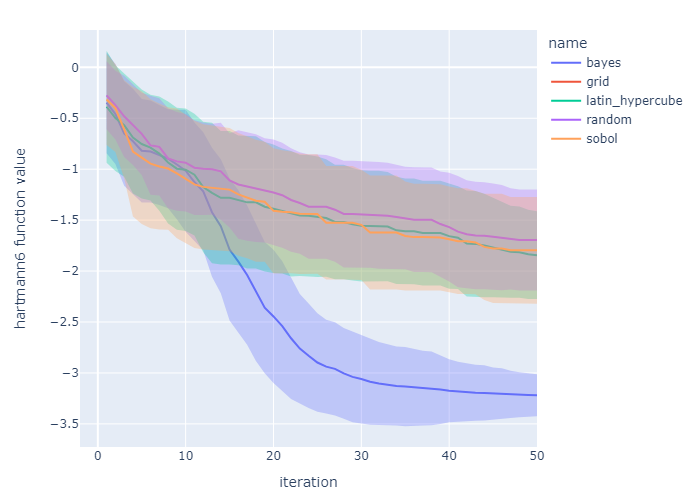

In [54]:
# For notebook gallery thumbnail
from IPython.display import Image
Image(filename=fig_path + ".png")

## Code Graveyard

In [22]:
# from ax.modelbridge.factory import get_sobol
# from ax.service.ax_client import AxClient

# def get_sobol_samples(bounds, num_samples=10):
#     parameters = [
#             {
#                 "name": "x1",
#                 "type": "range",
#                 "bounds": bounds["x1"],
#             },
#             {
#                 "name": "x2",
#                 "type": "range",
#                 "bounds": bounds["x2"],
#             },
#         ]

#     client = AxClient()
#     client.create_experiment(
#         name="experiment",
#         parameters=parameters,  # type: ignore
#     )
        
#     m = get_sobol(client.experiment.search_space)
#     gr = m.gen(n=num_samples)
#     gr

In [23]:
# compare_samples = {}
# for name, sampling_fn in sampling_fns.items():
#     compare_samples[name] = {}
#     for num_samples in sample_nums:
#         compare_samples[name][num_samples] = sampling_fn(bounds, num_samples)
        
# df = pd.DataFrame(compare_samples)
# df.index.name = "num_samples"
# df

In [24]:
# three_plot_df = three.copy()
# three_plot_df["step"] = (np.arange(0, three_plot_df.shape[0]))
# three_plot_df["group"] = 1

# px.scatter_3d(three_plot_df, x="x1", y="x2", z="x3", animation_frame="step", animation_group="group", width=400, height=400)


In [25]:
# discrepancies = []
# for name, sampling_fn in sampling_fns.items():
#     for num_samples in sample_nums:
#         sample_df = compare_df.query("name == @name and num_samples == @num_samples")
#         sample_df["discrepancy"] = qmc.discrepancy(sample_df[["x1", "x2"]].values)
#         sample_dfs.append(sample_df)

# compare_df_2 = pd.concat(sample_dfs, axis=0)
# compare_df_2